In [1]:
# Verificar la GPU para garantizar que el modelo funcione
# Para este ejercicio tiene que estar seleccionado el entorno GPU T4
!nvidia-smi

Sun Oct 11 21:59:35 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   37C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
# Instalación de librerías necesarias para el proyecto multimodal
!pip install -q transformers datasets evaluate huggingface_hub
!pip install -q torch torchvision Pillow pandas scikit-learn

print("Librerías instaladas")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.0 MB/s eta 0:00:00
¡Librerías instaladas correctamente!


In [5]:
# Autenticación segura con Hugging Face Hub
import os
from huggingface_hub import login
from google.colab import userdata

try:
    # Autenticar usando la variable de los Secrets
    login(token=userdata.get('HF_TOKEN'))
    print("Autenticación exitosa")
except Exception as e:
    # Si no esta configurada, ingresa el token a usar aqui
    login(token='PON AQUI TU TOKEN')
    print("Autenticación manual realizada")
    login()

Autenticación exitosa


In [4]:
import pandas as pd

# Definimos un catálogo de productos usando imágenes públicas y articulos comunes
datos_productos = {
    "id_producto": [1, 2, 3, 4],
    "url_imagen": [
        "https://images.unsplash.com/photo-1579586337278-3befd40fd17a", # Reloj inteligente deportivo
        "https://images.unsplash.com/photo-1590658268037-6bf12165a8df", # Audífonos inalámbricos in-ear
        "https://images.unsplash.com/photo-1580273916550-e323be2ae537", # Llanta de automóvil
        "https://images.unsplash.com/photo-1508685096489-7aacd43bd3b1"  # Reloj inteligente metálico
    ],
    "etiqueta_real": ["smartwatch", "audifonos inalambricos", "llantas de auto", "smartwatch"]
}

# Creamis el DataFrame
df_productos = pd.DataFrame(datos_productos)

# Exportamos el dataset a CSV
df_productos.to_csv("dataset_retail_busqueda.csv", index=False)

print("Dataset generado y guardado como 'dataset_retail_busqueda.csv'.")
display(df_productos)

Dataset generado y guardado exitosamente como 'dataset_retail_busqueda.csv'.
Puedes descargarlo desde el panel de 'Archivos' (ícono de carpeta) a la izquierda.


,id_producto,url_imagen,etiqueta_real
0,1,https://images.unsplash.com/photo-157958633727...,smartwatch
1,2,https://images.unsplash.com/photo-159065826803...,audifonos inalambricos
2,3,https://images.unsplash.com/photo-158027391655...,llantas de auto
3,4,https://images.unsplash.com/photo-150868509648...,smartwatch


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

...

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Resultados de Búsqueda Visual con CLIP
Categoría: smartwatch | Confianza: 0.9800
Categoría: reloj tradicional | Confianza: 0.0191
Categoría: smartphone | Confianza: 0.0007
Categoría: llantas de auto | Confianza: 0.0001
Categoría: audifonos inalambricos | Confianza: 0.0001


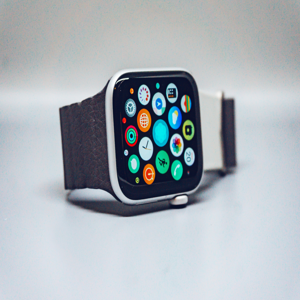

In [5]:
from transformers import pipeline
from PIL import Image
import requests

# Cargamos el pipeline multimodal (Zero-Shot Image Classification)
clasificador_clip = pipeline("zero-shot-image-classification", model="openai/clip-vit-base-patch32", device=0)

# Seleccionamos nuestra primer imagen
url_prueba = df_productos["url_imagen"][0]
imagen_prueba = Image.open(requests.get(url_prueba, stream=True).raw)

# Difinimos las posibles categorías de búsqueda
categorias_busqueda = ["smartwatch", "audifonos inalambricos", "llantas de auto", "smartphone", "reloj tradicional"]

# Ejecutamos el modelo predictivo
resultados_clip = clasificador_clip(imagen_prueba, candidate_labels=categorias_busqueda)

# Resultados ordenados por probabilidad
print("Resultados de Búsqueda Visual con CLIP")
for res in resultados_clip:
    print(f"Categoría: {res['label']} | Confianza: {res['score']:.4f}")

display(imagen_prueba.resize((300, 300)))

In [6]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from PIL import Image
import requests

# Creamos listas para almacenar los resultados del ciclo
etiquetas_reales = df_productos["etiqueta_real"].tolist()
etiquetas_predichas = []
tiempos_inferencia = []

print("Procesando imágenes y calculando predicciones...")

# Iteramos sobre cada fila del dataset
for index, row in df_productos.iterrows():
    # Cargamos la imagen
    imagen = Image.open(requests.get(row["url_imagen"], stream=True).raw)

    # Iniciamos un cronómetro
    inicio_tiempo = time.time()

    # Ejecutamos inferencia zero-shot
    resultado = clasificador_clip(imagen, candidate_labels=categorias_busqueda)

    # Detenemos cronómetro
    fin_tiempo = time.time()

    # La predicción con mayor probabilidad siempre está en el índice 0
    mejor_prediccion = resultado[0]["label"]

    # Almacenamos los resultados
    etiquetas_predichas.append(mejor_prediccion)
    tiempos_inferencia.append(fin_tiempo - inicio_tiempo)

# Calculo de métricas estandarizadas
accuracy = accuracy_score(etiquetas_reales, etiquetas_predichas)
precision = precision_score(etiquetas_reales, etiquetas_predichas, average='macro', zero_division=0)
recall = recall_score(etiquetas_reales, etiquetas_predichas, average='macro', zero_division=0)
f1 = f1_score(etiquetas_reales, etiquetas_predichas, average='macro', zero_division=0)

# Medimos el tiempo promedio de inferencia
tiempo_promedio = sum(tiempos_inferencia) / len(tiempos_inferencia)

# Mstramos resultados
print("\n" + "="*50)
print("   RESULTADOS DE EVALUACIÓN: OPENAI CLIP-ViT")
print("="*50)
print(f"Exactitud (Accuracy):  {accuracy:.4f}")
print(f"Precisión (Precision): {precision:.4f}")
print(f"Exhaustividad (Recall):{recall:.4f}")
print(f"Puntuación F1 (F1):    {f1:.4f}")
print("-" * 50)
print(f"Tiempo promedio:     {tiempo_promedio:.4f} segundos/imagen")
print("="*50)

Procesando imágenes y calculando predicciones...

   RESULTADOS DE EVALUACIÓN: OPENAI CLIP-ViT
Exactitud (Accuracy):  0.7500
Precisión (Precision): 0.5556
Exhaustividad (Recall):0.6667
Puntuación F1 (F1):    0.6000
--------------------------------------------------
Latencia promedio:     0.4888 segundos/imagen


In [8]:
import time
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from transformers import pipeline
from PIL import Image
import requests

# Cargamos modelos de clasificación tradicional en GPU
vit_pipeline = pipeline("image-classification", model="google/vit-base-patch16-224", device=0)
resnet_pipeline = pipeline("image-classification", model="microsoft/resnet-50", device=0)

print("Procesando imágenes y calculando predicciones para ViT y ResNet...")

etiquetas_reales = df_productos["etiqueta_real"].tolist()
predicciones_vit = []
predicciones_resnet = []
tiempos_vit = []
tiempos_resnet = []

# Iteramos sobre el dataset
for index, row in df_productos.iterrows():
    imagen = Image.open(requests.get(row["url_imagen"], stream=True).raw)

    # ViT
    inicio = time.time()
    res_vit = vit_pipeline(imagen)
    tiempos_vit.append(time.time() - inicio)
    predicciones_vit.append(res_vit[0]['label'])

    # ResNet
    inicio = time.time()
    res_resnet = resnet_pipeline(imagen)
    tiempos_resnet.append(time.time() - inicio)
    predicciones_resnet.append(res_resnet[0]['label'])

# Métricas para ViT
acc_vit = accuracy_score(etiquetas_reales, predicciones_vit)
prec_vit = precision_score(etiquetas_reales, predicciones_vit, average='macro', zero_division=0)
rec_vit = recall_score(etiquetas_reales, predicciones_vit, average='macro', zero_division=0)
f1_vit = f1_score(etiquetas_reales, predicciones_vit, average='macro', zero_division=0)
tiempo_vit = sum(tiempos_vit) / len(tiempos_vit)

# Métricas para ResNet
acc_resnet = accuracy_score(etiquetas_reales, predicciones_resnet)
prec_resnet = precision_score(etiquetas_reales, predicciones_resnet, average='macro', zero_division=0)
rec_resnet = recall_score(etiquetas_reales, predicciones_resnet, average='macro', zero_division=0)
f1_resnet = f1_score(etiquetas_reales, predicciones_resnet, average='macro', zero_division=0)
tiempo_resnet = sum(tiempos_resnet) / len(tiempos_resnet)

# Resultados para cada modelo
print("\n" + "="*50)
print("   RESULTADOS: GOOGLE ViT-BASE")
print("="*50)
print(f"Exactitud (Accuracy):  {acc_vit:.4f}")
print(f"Precisión (Precision): {prec_vit:.4f}")
print(f"Exhaustividad (Recall):{rec_vit:.4f}")
print(f"Puntuación F1 (F1):    {f1_vit:.4f}")
print("-" * 50)
print(f"Tiempo promedio:       {tiempo_vit:.4f} segundos/imagen")
print("="*50)

print("\n" + "="*50)
print("   RESULTADOS: MICROSOFT RESNET-50")
print("="*50)
print(f"Exactitud (Accuracy):  {acc_resnet:.4f}")
print(f"Precisión (Precision): {prec_resnet:.4f}")
print(f"Exhaustividad (Recall):{rec_resnet:.4f}")
print(f"Puntuación F1 (F1):    {f1_resnet:.4f}")
print("-" * 50)
print(f"Tiempo promedio:       {tiempo_resnet:.4f} segundos/imagen")
print("="*50)

# Mstramos resultados del moedlo CLIP-ViT para compararlos visualmente
print("\n" + "="*50)
print("   RESULTADOS: OPENAI CLIP-ViT")
print("="*50)
print(f"Exactitud (Accuracy):  {accuracy:.4f}")
print(f"Precisión (Precision): {precision:.4f}")
print(f"Exhaustividad (Recall):{recall:.4f}")
print(f"Puntuación F1 (F1):    {f1:.4f}")
print("-" * 50)
print(f"Tiempo promedio:     {tiempo_promedio:.4f} segundos/imagen")
print("="*50)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Procesando imágenes y calculando predicciones para ViT y ResNet...

   RESULTADOS: GOOGLE ViT-BASE
Exactitud (Accuracy):  0.0000
Precisión (Precision): 0.0000
Exhaustividad (Recall):0.0000
Puntuación F1 (F1):    0.0000
--------------------------------------------------
Tiempo promedio:       0.4058 segundos/imagen

   RESULTADOS: MICROSOFT RESNET-50
Exactitud (Accuracy):  0.0000
Precisión (Precision): 0.0000
Exhaustividad (Recall):0.0000
Puntuación F1 (F1):    0.0000
--------------------------------------------------
Tiempo promedio:       0.1217 segundos/imagen

   RESULTADOS: OPENAI CLIP-ViT
Exactitud (Accuracy):  0.7500
Precisión (Precision): 0.5556
Exhaustividad (Recall):0.6667
Puntuación F1 (F1):    0.6000
--------------------------------------------------
Tiempo promedio:     0.4888 segundos/imagen
